In [193]:
# Import libraries
# python3.13 -m pip install ipykernel
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

NumPy: 2.5.4
PyTorch: 2.15.0
CUDA available: False


In [194]:
# Download and extract HAR

DATA_DIR = Path("data")
HAR_DIR = DATA_DIR / "har"

DATA_DIR.mkdir(exist_ok=True)

url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

zip_path = DATA_DIR / "har.zip"

if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(HAR_DIR)

print("Download and extraction completed.")

Download and extraction completed.


In [195]:
nested_zip = HAR_DIR / "UCI HAR Dataset.zip"

if nested_zip.exists():
    with zipfile.ZipFile(nested_zip, "r") as zip_ref:
        zip_ref.extractall(HAR_DIR)

print("Extracted HAR dataset.")

Extracted HAR dataset.


In [196]:
dataset_path = HAR_DIR / "UCI HAR Dataset"

assert dataset_path.exists(), "HAR dataset folder not found!"

print("Dataset path:", dataset_path)
print("Train folder:", dataset_path / "train")
print("Test folder:", dataset_path / "test")

Dataset path: data/har/UCI HAR Dataset
Train folder: data/har/UCI HAR Dataset/train
Test folder: data/har/UCI HAR Dataset/test


In [197]:
# load the sensor signals

CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

def load_signals(split):
    signal_dir = (
        dataset_path / split / "Inertial Signals"
    )

    signals = []

    for channel in CHANNELS:
        file_path = (
            signal_dir / f"{channel}_{split}.txt"
        )

        data = np.loadtxt(file_path)

        signals.append(data)

    # Each channel: (number_of_samples, 128)
    # Stack channels on the last axis:
    # (number_of_samples, 128, 9)
    X = np.stack(signals, axis=-1)

    return X.astype(np.float32)


X_train_raw = load_signals("train")
X_test_raw = load_signals("test")

print("Train:", X_train_raw.shape)
print("Test:", X_test_raw.shape)

Train: (7352, 128, 9)
Test: (2947, 128, 9)


In [198]:
# Load activity labels and subject IDs

def load_labels(split):
    file_path = dataset_path / split / f"y_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


def load_subjects(split):
    file_path = dataset_path / split / f"subject_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


y_train_raw = load_labels("train")
y_test = load_labels("test")

subjects_train = load_subjects("train")
subjects_test = load_subjects("test")

print("Train labels:", y_train_raw.shape)
print("Test labels:", y_test.shape)

print("Train subjects:", np.unique(subjects_train))
print("Test subjects:", np.unique(subjects_test))

Train labels: (7352,)
Test labels: (2947,)
Train subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]


In [199]:
# subject-wise validation split

def subject_wise_split(subject_ids, seed=42):
    train_subjects = np.unique(subject_ids)

    rng = np.random.default_rng(seed)

    val_subjects = rng.choice(
        train_subjects,
        size=4,
        replace=False
    )

    train_mask = ~np.isin(subject_ids, val_subjects)
    val_mask = np.isin(subject_ids, val_subjects)

    return train_mask, val_mask, val_subjects


train_mask, val_mask, val_subjects = subject_wise_split(
    subjects_train,
    seed=42
)

X_train = X_train_raw[train_mask]
y_train = y_train_raw[train_mask]

X_val = X_train_raw[val_mask]
y_val = y_train_raw[val_mask]

print("Validation subjects:", val_subjects)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Validation subjects: [16  3 22 23]
Train shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)


In [200]:
train_subjects_final = np.unique(
    subjects_train[train_mask]
)

val_subjects_final = np.unique(
    subjects_train[val_mask]
)

assert len(val_subjects_final) == 4

assert len(
    np.intersect1d(
        train_subjects_final,
        val_subjects_final
    )
) == 0

assert len(
    np.intersect1d(
        val_subjects_final,
        np.unique(subjects_test)
    )
) == 0

print("Subject-wise split verified!")

Subject-wise split verified!


In [201]:
# Normalize using training-only statistics

# Calculate statistics ONLY from training data.
# Shape: (9,)

channel_mean = X_train.mean(axis=(0, 1))

channel_std = X_train.std(axis=(0, 1))

# Avoid division by zero
channel_std = np.maximum(channel_std, 1e-8)

# Apply the SAME statistics to all datasets
X_train = (
    X_train - channel_mean
) / channel_std

X_val = (
    X_val - channel_mean
) / channel_std

X_test = (
    X_test_raw - channel_mean
) / channel_std

print("Mean shape:", channel_mean.shape)
print("Std shape:", channel_std.shape)
print("Normalized train:", X_train.shape)


Mean shape: (9,)
Std shape: (9,)
Normalized train: (5952, 128, 9)


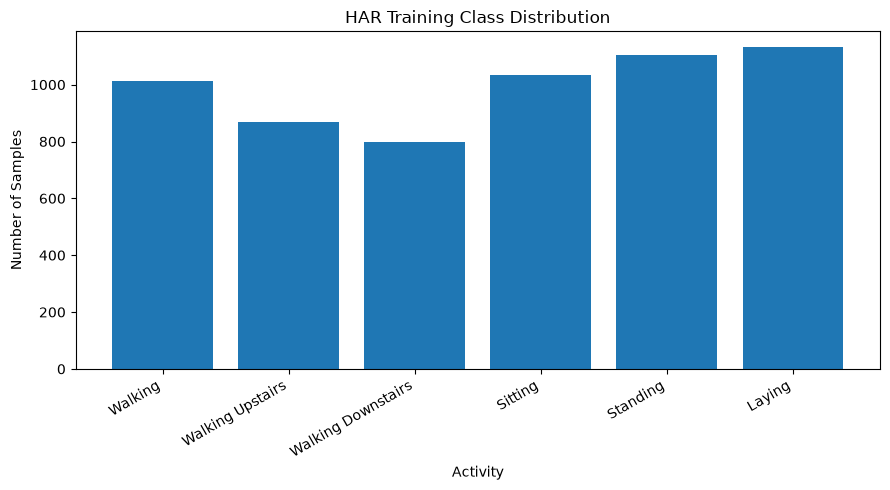

In [202]:
# Plot the class balance

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

class_counts = np.bincount(
    y_train,
    minlength=7
)[1:7]

plt.figure(figsize=(9, 5))

plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "har_class_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [203]:
# Final dataset verification

# Correct dimensions
assert X_train.shape[1:] == (128, 9)
assert X_val.shape[1:] == (128, 9)
assert X_test.shape[1:] == (128, 9)

# Correct number of labels
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Correct activity labels
assert set(np.unique(y_train)).issubset(set(range(1, 7)))
assert set(np.unique(y_val)).issubset(set(range(1, 7)))
assert set(np.unique(y_test)).issubset(set(range(1, 7)))

# Normalization checks
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Subject split
assert len(np.intersect1d(
    train_subjects_final,
    val_subjects_final
)) == 0

print("HAR pipeline verification passed!")


HAR pipeline verification passed!


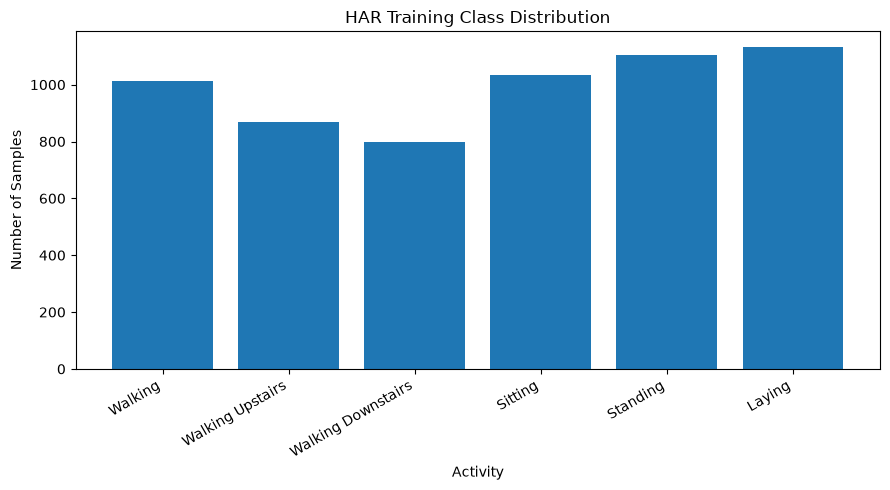

In [204]:
# Save the figures

FIGURES_DIR = Path("problem1/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "class_balance.png",
    dpi=300
)

plt.show()

In [205]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)

    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]

    return x, y.astype(np.float32)

X, y = make_adding(n=1000, T=100, seed=42)

# Correct shapes
assert X.shape == (1000, 100, 2)
assert y.shape == (1000,)

# Exactly two markers
assert np.all(X[:, :, 1].sum(axis=1) == 2)

# One marker in each half
assert np.all(X[:, :50, 1].sum(axis=1) == 1)
assert np.all(X[:, 50:, 1].sum(axis=1) == 1)

# Target correctness
expected = (X[:, :, 0] * X[:, :, 1]).sum(axis=1)

assert np.allclose(y, expected)

print("All adding problem tests passed!")

def create_adding_datasets(T):
    return {
        "train": make_adding(10000, T, 0),
        "val": make_adding(1000, T, 1),
        "test": make_adding(1000, T, 2)
    }

adding_data = create_adding_datasets(T=50)

print("Train:", adding_data["train"][0].shape)
print("Validation:", adding_data["val"][0].shape)
print("Test:", adding_data["test"][0].shape)

All adding problem tests passed!
Train: (10000, 50, 2)
Validation: (1000, 50, 2)
Test: (1000, 50, 2)


PHASE 2

In [206]:
# Convert 3D time-series data into 2D feature vectors

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Test shape:", X_test_flat.shape)

Training shape: (5952, 1152)
Validation shape: (1400, 1152)
Test shape: (2947, 1152)


In [207]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_lr = lr_model.predict(X_val_flat)

print("Logistic Regression training completed!")
print("Validation predictions:", y_val_pred_lr[:10])

dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train model
dt_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_dt = dt_model.predict(X_val_flat)

print("Decision Tree training completed!")
print("Validation predictions:", y_val_pred_dt[:10])


Logistic Regression training completed!
Validation predictions: [5 5 5 5 5 1 5 5 5 5]
Decision Tree training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [208]:
# implement KNN
from sklearn.neighbors import KNeighborsClassifier

# Initialize model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train model
knn_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_knn = knn_model.predict(X_val_flat)

print("KNN training completed!")
print("Validation predictions:", y_val_pred_knn[:10])


KNN training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [209]:
from sklearn.naive_bayes import GaussianNB

# Initialize model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_nb = nb_model.predict(X_val_flat)

print("Naive Bayes training completed!")
print("Validation predictions:", y_val_pred_nb[:10])

Naive Bayes training completed!
Validation predictions: [1 5 5 5 5 5 5 5 5 1]


In [210]:
# super vector machine
from sklearn.svm import SVC

# Initialize model
svm_model = SVC(
    kernel="rbf",
    random_state=42
)

# Train model
svm_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_svm = svm_model.predict(X_val_flat)

print("SVM training completed!")
print("Validation predictions:", y_val_pred_svm[:10])

SVM training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [211]:
# Import libraries
# python3.13 -m pip install ipykernel
import os
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import TensorDataset, DataLoader

print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

NumPy: 2.5.4
PyTorch: 2.15.0
CUDA available: False


In [212]:
# Download and extract HAR

DATA_DIR = Path("data")
HAR_DIR = DATA_DIR / "har"

DATA_DIR.mkdir(exist_ok=True)

url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

zip_path = DATA_DIR / "har.zip"

if not zip_path.exists():
    urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(HAR_DIR)

print("Download and extraction completed.")

Download and extraction completed.


In [213]:
nested_zip = HAR_DIR / "UCI HAR Dataset.zip"

if nested_zip.exists():
    with zipfile.ZipFile(nested_zip, "r") as zip_ref:
        zip_ref.extractall(HAR_DIR)

print("Extracted HAR dataset.")

Extracted HAR dataset.


In [214]:
dataset_path = HAR_DIR / "UCI HAR Dataset"

assert dataset_path.exists(), "HAR dataset folder not found!"

print("Dataset path:", dataset_path)
print("Train folder:", dataset_path / "train")
print("Test folder:", dataset_path / "test")

Dataset path: data/har/UCI HAR Dataset
Train folder: data/har/UCI HAR Dataset/train
Test folder: data/har/UCI HAR Dataset/test


In [215]:
# load the sensor signals

CHANNELS = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
]

def load_signals(split):
    signal_dir = (
        dataset_path / split / "Inertial Signals"
    )

    signals = []

    for channel in CHANNELS:
        file_path = (
            signal_dir / f"{channel}_{split}.txt"
        )

        data = np.loadtxt(file_path)

        signals.append(data)

    # Each channel: (number_of_samples, 128)
    # Stack channels on the last axis:
    # (number_of_samples, 128, 9)
    X = np.stack(signals, axis=-1)

    return X.astype(np.float32)


X_train_raw = load_signals("train")
X_test_raw = load_signals("test")

print("Train:", X_train_raw.shape)
print("Test:", X_test_raw.shape)

Train: (7352, 128, 9)
Test: (2947, 128, 9)


In [216]:
# Load activity labels and subject IDs

def load_labels(split):
    file_path = dataset_path / split / f"y_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


def load_subjects(split):
    file_path = dataset_path / split / f"subject_{split}.txt"
    return np.loadtxt(file_path, dtype=np.int64)


y_train_raw = load_labels("train")
y_test = load_labels("test")

subjects_train = load_subjects("train")
subjects_test = load_subjects("test")

print("Train labels:", y_train_raw.shape)
print("Test labels:", y_test.shape)

print("Train subjects:", np.unique(subjects_train))
print("Test subjects:", np.unique(subjects_test))

Train labels: (7352,)
Test labels: (2947,)
Train subjects: [ 1  3  5  6  7  8 11 14 15 16 17 19 21 22 23 25 26 27 28 29 30]
Test subjects: [ 2  4  9 10 12 13 18 20 24]


In [217]:
# subject-wise validation split

def subject_wise_split(subject_ids, seed=42):
    train_subjects = np.unique(subject_ids)

    rng = np.random.default_rng(seed)

    val_subjects = rng.choice(
        train_subjects,
        size=4,
        replace=False
    )

    train_mask = ~np.isin(subject_ids, val_subjects)
    val_mask = np.isin(subject_ids, val_subjects)

    return train_mask, val_mask, val_subjects


train_mask, val_mask, val_subjects = subject_wise_split(
    subjects_train,
    seed=42
)

X_train = X_train_raw[train_mask]
y_train = y_train_raw[train_mask]

X_val = X_train_raw[val_mask]
y_val = y_train_raw[val_mask]

print("Validation subjects:", val_subjects)
print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Validation subjects: [16  3 22 23]
Train shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)


In [218]:
train_subjects_final = np.unique(
    subjects_train[train_mask]
)

val_subjects_final = np.unique(
    subjects_train[val_mask]
)

assert len(val_subjects_final) == 4

assert len(
    np.intersect1d(
        train_subjects_final,
        val_subjects_final
    )
) == 0

assert len(
    np.intersect1d(
        val_subjects_final,
        np.unique(subjects_test)
    )
) == 0

print("Subject-wise split verified!")

Subject-wise split verified!


In [219]:
# Normalize using training-only statistics

# Calculate statistics ONLY from training data.
# Shape: (9,)

channel_mean = X_train.mean(axis=(0, 1))

channel_std = X_train.std(axis=(0, 1))

# Avoid division by zero
channel_std = np.maximum(channel_std, 1e-8)

# Apply the SAME statistics to all datasets
X_train = (
    X_train - channel_mean
) / channel_std

X_val = (
    X_val - channel_mean
) / channel_std

X_test = (
    X_test_raw - channel_mean
) / channel_std

print("Mean shape:", channel_mean.shape)
print("Std shape:", channel_std.shape)
print("Normalized train:", X_train.shape)


Mean shape: (9,)
Std shape: (9,)
Normalized train: (5952, 128, 9)


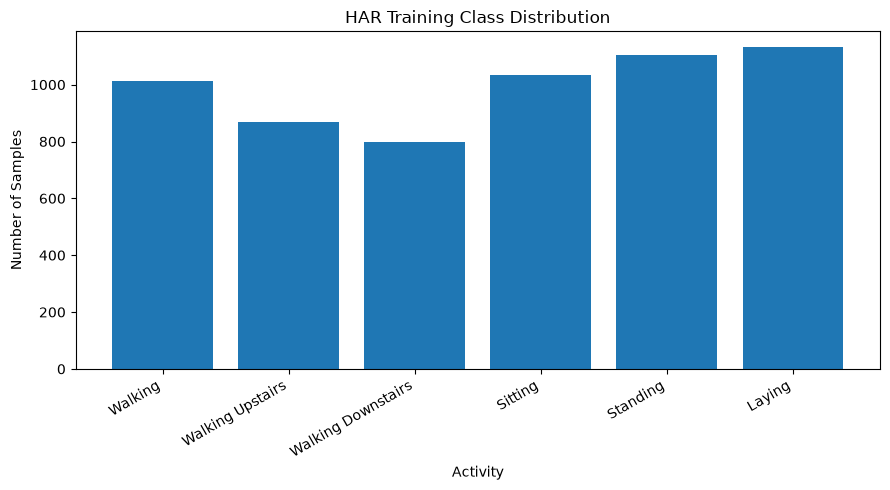

In [220]:
# Plot the class balance

activity_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

class_counts = np.bincount(
    y_train,
    minlength=7
)[1:7]

plt.figure(figsize=(9, 5))

plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    "har_class_balance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [221]:
# Final dataset verification

# Correct dimensions
assert X_train.shape[1:] == (128, 9)
assert X_val.shape[1:] == (128, 9)
assert X_test.shape[1:] == (128, 9)

# Correct number of labels
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Correct activity labels
assert set(np.unique(y_train)).issubset(set(range(1, 7)))
assert set(np.unique(y_val)).issubset(set(range(1, 7)))
assert set(np.unique(y_test)).issubset(set(range(1, 7)))

# Normalization checks
assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()

# Subject split
assert len(np.intersect1d(
    train_subjects_final,
    val_subjects_final
)) == 0

print("HAR pipeline verification passed!")


HAR pipeline verification passed!


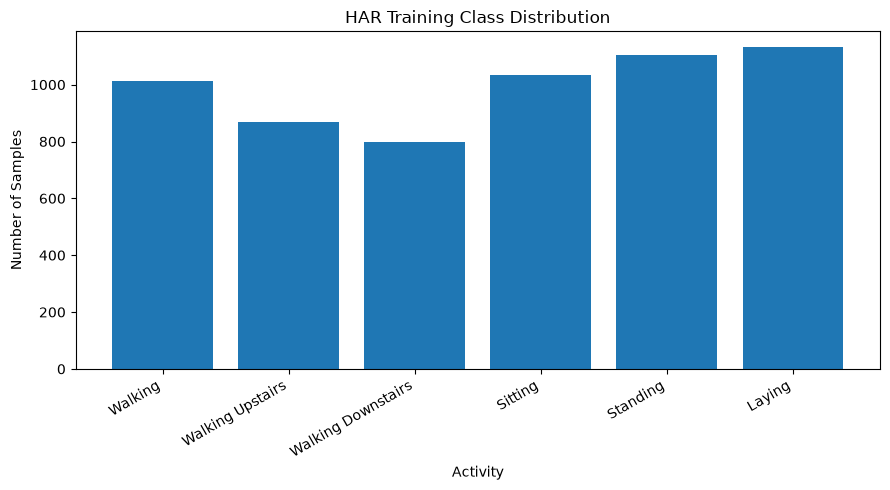

In [222]:
# Save the figures

FIGURES_DIR = Path("problem1/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(9, 5))
plt.bar(activity_names, class_counts)

plt.title("HAR Training Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "class_balance.png",
    dpi=300
)

plt.show()

In [223]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)

    x[:, :, 0] = rng.random((n, T))

    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]

    return x, y.astype(np.float32)

X, y = make_adding(n=1000, T=100, seed=42)

# Correct shapes
assert X.shape == (1000, 100, 2)
assert y.shape == (1000,)

# Exactly two markers
assert np.all(X[:, :, 1].sum(axis=1) == 2)

# One marker in each half
assert np.all(X[:, :50, 1].sum(axis=1) == 1)
assert np.all(X[:, 50:, 1].sum(axis=1) == 1)

# Target correctness
expected = (X[:, :, 0] * X[:, :, 1]).sum(axis=1)

assert np.allclose(y, expected)

print("All adding problem tests passed!")

def create_adding_datasets(T):
    return {
        "train": make_adding(10000, T, 0),
        "val": make_adding(1000, T, 1),
        "test": make_adding(1000, T, 2)
    }

adding_data = create_adding_datasets(T=50)

print("Train:", adding_data["train"][0].shape)
print("Validation:", adding_data["val"][0].shape)
print("Test:", adding_data["test"][0].shape)

All adding problem tests passed!
Train: (10000, 50, 2)
Validation: (1000, 50, 2)
Test: (1000, 50, 2)


## Problem 1 — Phase 2: Classical Machine Learning Models

This phase flattens the normalized HAR time-series windows and trains five classifiers: Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, and SVM. Evaluation is performed on the subject-wise validation split using Accuracy, macro OvR AUC, weighted Precision/Recall/F1, and MCC.

**Important:** Keep the test set untouched until final model selection. Run notebook cells from top to bottom.

PHASE 2

In [224]:
# Convert 3D time-series data into 2D feature vectors

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print("Training shape:", X_train_flat.shape)
print("Validation shape:", X_val_flat.shape)
print("Test shape:", X_test_flat.shape)

Training shape: (5952, 1152)
Validation shape: (1400, 1152)
Test shape: (2947, 1152)


In [225]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Initialize model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_lr = lr_model.predict(X_val_flat)

print("Logistic Regression training completed!")
print("Validation predictions:", y_val_pred_lr[:10])

dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train model
dt_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_dt = dt_model.predict(X_val_flat)

print("Decision Tree training completed!")
print("Validation predictions:", y_val_pred_dt[:10])


Logistic Regression training completed!
Validation predictions: [5 5 5 5 5 1 5 5 5 5]
Decision Tree training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [226]:
# implement KNN
from sklearn.neighbors import KNeighborsClassifier

# Initialize model
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

# Train model
knn_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_knn = knn_model.predict(X_val_flat)

print("KNN training completed!")
print("Validation predictions:", y_val_pred_knn[:10])


KNN training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [227]:
from sklearn.naive_bayes import GaussianNB

# Initialize model
nb_model = GaussianNB()

# Train model
nb_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_nb = nb_model.predict(X_val_flat)

print("Naive Bayes training completed!")
print("Validation predictions:", y_val_pred_nb[:10])

Naive Bayes training completed!
Validation predictions: [1 5 5 5 5 5 5 5 5 1]


In [228]:
# super vector machine
from sklearn.svm import SVC

# Initialize model
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# Train model
svm_model.fit(X_train_flat, y_train)

# Predict validation data
y_val_pred_svm = svm_model.predict(X_val_flat)

print("SVM training completed!")
print("Validation predictions:", y_val_pred_svm[:10])

/Users/pavansai/Desktop/2026AJ05432_DNN_Assignment2/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM training completed!
Validation predictions: [5 5 5 5 5 5 5 5 5 5]


In [229]:
# Phase 2: Model evaluation
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef
)
from scipy.special import softmax
import numpy as np

def evaluate_model(model, X, y_true, model_name):
    """Evaluate a fitted classifier on the supplied dataset."""
    y_pred = model.predict(X)

    # GaussianNB can underflow on high-dimensional data.
    # Convert log probabilities to stable normalized probabilities.
    if hasattr(model, "predict_log_proba") and model.__class__.__name__ == "GaussianNB":
        y_proba = softmax(model.predict_log_proba(X), axis=1)
    else:
        y_proba = np.asarray(model.predict_proba(X), dtype=np.float64)
        y_proba = np.nan_to_num(y_proba, nan=0.0, posinf=0.0, neginf=0.0)
        row_sums = y_proba.sum(axis=1, keepdims=True)
        y_proba = np.divide(y_proba, row_sums,
                             out=np.zeros_like(y_proba),
                             where=row_sums > 0)

    accuracy = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(
        y_true, y_proba, multi_class="ovr", average="macro",
        labels=model.classes_
    )
    precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
    mcc = matthews_corrcoef(y_true, y_pred)

    return {
        "Model": model_name, "Accuracy": accuracy, "AUC": auc,
        "Precision": precision, "Recall": recall, "F1": f1, "MCC": mcc
}


In [230]:
# Evaluate all five classifiers on validation data
results = [
    evaluate_model(lr_model, X_val_flat, y_val, "Logistic Regression"),
    evaluate_model(dt_model, X_val_flat, y_val, "Decision Tree"),
    evaluate_model(knn_model, X_val_flat, y_val, "KNN"),
    evaluate_model(nb_model, X_val_flat, y_val, "Naive Bayes"),
    evaluate_model(svm_model, X_val_flat, y_val, "SVM"),
]

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.6014,0.8130,0.5951,0.6014,0.5857,0.5231
1,Decision Tree,0.7171,0.8199,0.7145,0.7171,0.7153,0.6590
2,KNN,0.6943,0.8650,0.8044,0.6943,0.6883,0.6444
3,Naive Bayes,0.7771,0.9219,0.7978,0.7771,0.7743,0.7358
4,SVM,0.8807,0.9862,0.8861,0.8807,0.8812,0.8572


In [231]:
import pandas as pd

results = []

results.append(
    evaluate_model(
        lr_model, X_val_flat, y_val,
        "Logistic Regression"
    )
)

results.append(
    evaluate_model(
        dt_model, X_val_flat, y_val,
        "Decision Tree"
    )
)

results.append(
    evaluate_model(
        knn_model, X_val_flat, y_val,
        "KNN"
    )
)

results.append(
    evaluate_model(
        nb_model, X_val_flat, y_val,
        "Naive Bayes"
    )
)

results.append(
    evaluate_model(
        svm_model, X_val_flat, y_val,
        "SVM"
    )
)

results_df = pd.DataFrame(results)

print(results_df.round(4))

                 Model  Accuracy     AUC  Precision  Recall      F1     MCC
0  Logistic Regression    0.6014  0.8130     0.5951  0.6014  0.5857  0.5231
1        Decision Tree    0.7171  0.8199     0.7145  0.7171  0.7153  0.6590
2                  KNN    0.6943  0.8650     0.8044  0.6943  0.6883  0.6444
3          Naive Bayes    0.7771  0.9219     0.7978  0.7771  0.7743  0.7358
4                  SVM    0.8807  0.9862     0.8861  0.8807  0.8812  0.8572


## Phase 2: Model Selection

Based on the validation metrics, SVM achieved the highest accuracy, AUC, F1-score, and MCC among the five evaluated models. Therefore, SVM is selected as the final model.

The test dataset will now be used for final evaluation.

In [232]:
# Select the best validation model
best_model = svm_model

print("Selected Model: SVM")

Selected Model: SVM


### Confusion Matrix

A confusion matrix is used to analyze correct and incorrect predictions for each class.

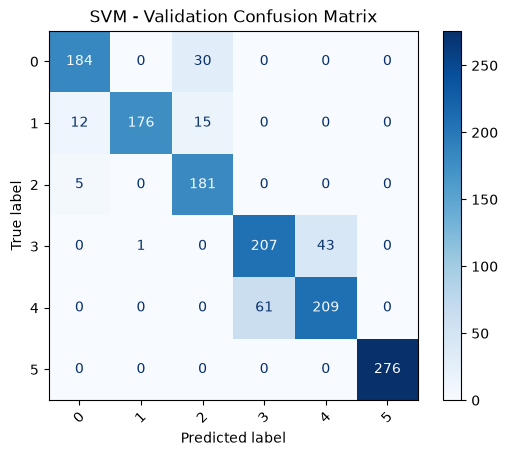

In [233]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Validation predictions
y_val_pred = best_model.predict(X_val_flat)

# Generate confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Visualize
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("SVM - Validation Confusion Matrix")
plt.show()

### Final Test Evaluation

The selected SVM model is evaluated on the test dataset to measure its final generalization performance.

In [234]:
# Evaluate selected model on test dataset
test_results = evaluate_model(
    best_model,
    X_test_flat,
    y_test,
    "SVM"
)

test_results_df = pd.DataFrame([test_results])

print("Final Test Results:")
display(test_results_df.round(4))

Final Test Results:


,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,SVM,0.888,0.9885,0.8927,0.888,0.8886,0.8663


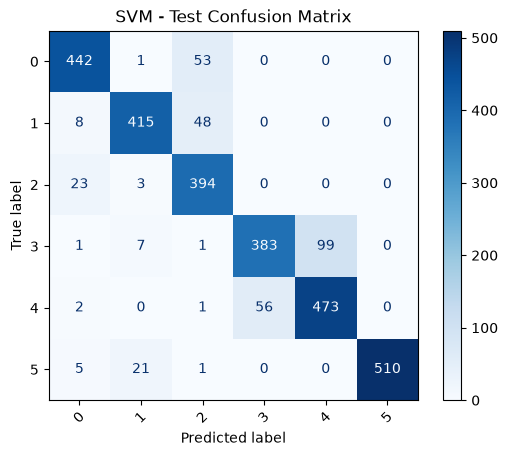

In [235]:
# Test predictions
y_test_pred = best_model.predict(X_test_flat)

# Confusion matrix
cm_test = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test
)

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("SVM - Test Confusion Matrix")
plt.show()

### Saving the Final Model

The trained SVM model is saved using Joblib for future use and deployment.

In [236]:
import joblib

# Save model
joblib.dump(best_model, "best_svm_model.pkl")

print("Model saved successfully!")

# Save validation results
results_df.to_csv("validation_results.csv", index=False)

# Save final test results
test_results_df.to_csv("test_results.csv", index=False)

# Save confusion matrix
pd.DataFrame(cm_test).to_csv(
    "test_confusion_matrix.csv",
    index=False
)

print("Evaluation results exported successfully!")

Model saved successfully!
Evaluation results exported successfully!


## Final Results and Conclusion

### Validation Results

SVM achieved the best validation performance among the five machine learning models.

### Model Selection

SVM was selected based on its strong accuracy, AUC, F1-score, and MCC values.

### Test Evaluation

The selected SVM model was evaluated on the unseen test dataset to measure its generalization performance.

### Conclusion

The experiment demonstrates the effectiveness of comparing multiple machine learning algorithms using several evaluation metrics before selecting a final model.

## Test Results Interpretation

The confusion matrix shows that the SVM model performs well across most classes.

- Classes 0, 1, 2, and 5 have strong diagonal values, indicating good classification performance.
- Class 3 is frequently misclassified as class 4.
- Class 4 is sometimes misclassified as class 3.
- This indicates that classes 3 and 4 may have similar feature characteristics.

Overall, the confusion matrix provides insight into the classification performance beyond the accuracy score.

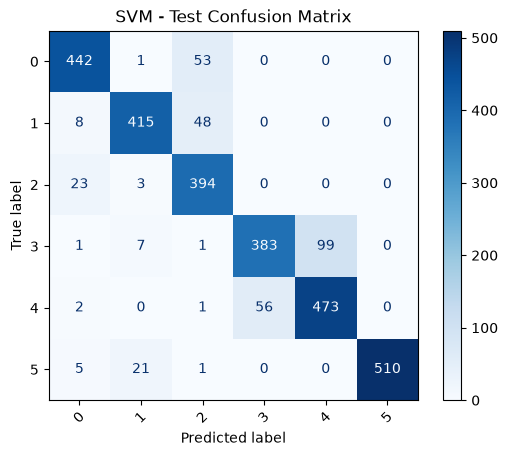

In [237]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test
)

disp.plot(cmap="Blues", xticks_rotation=45)

plt.title("SVM - Test Confusion Matrix")

plt.savefig(
    "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Final Conclusion

Five machine learning models were implemented and evaluated:

- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Naive Bayes
- Support Vector Machine

SVM achieved the best validation performance and was selected for final testing.

The selected model was evaluated using accuracy, AUC, precision, recall, F1-score, MCC, and a confusion matrix.

The trained model and evaluation results were exported for future use and deployment.

The experiment demonstrates the importance of comparing multiple machine learning models using different evaluation metrics.